In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score
)

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 6)
print("✅ Libraries successfully loaded!")


✅ Libraries successfully loaded!


In [2]:
data_path = '../data/proccessed/processed_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'data/proccessed/processed_dataset.csv'

df = pd.read_csv(data_path)
print(f"Loaded Cleaned Dataset: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(3)


Loaded Cleaned Dataset: 7043 rows, 1163 columns


,Latitude,Longitude,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Paperless Billing,Monthly Charges,Total Charges,...,Tech Support_Yes,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,33.964131,-118.272783,0,0,0,2,1,1,53.85,108.15,...,0,0,0,0,0,0,0,0,0,1
1,34.059281,-118.307420,0,0,1,2,1,1,70.70,151.65,...,0,0,0,0,0,0,0,0,1,0
2,34.048013,-118.293953,0,0,1,8,1,1,99.65,820.50,...,0,0,1,0,1,0,0,0,1,0


In [3]:
y = df['Churn Value']

drop_cols = ['Churn Value']
if 'Churn Reason' in df.columns:
    drop_cols.append('Churn Reason')

X = df.drop(columns=drop_cols)

print(f"Feature Matrix Shape: {X.shape}")
print("Target Value Counts:")
print(y.value_counts())
print(f"Stayed (0): {(y == 0).sum()} | Churned (1): {(y == 1).sum()}")


Feature Matrix Shape: (7043, 1161)
Target Value Counts:
Churn Value
0    5174
1    1869
Name: count, dtype: int64
Stayed (0): 5174 | Churned (1): 1869


In [4]:
continuous_cols = [col for col in ['Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges'] if col in X.columns]

scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[continuous_cols] = scaler.fit_transform(X_scaled[continuous_cols])

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set:  {X_test.shape[0]} samples")


Training set: 5634 samples
Testing set:  1409 samples


In [5]:
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42, n_jobs=-1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
        n_jobs=-1
    )
    cv_results[name] = {
        'CV Accuracy': f"{scores['test_accuracy'].mean():.4f} (±{scores['test_accuracy'].std():.3f})",
        'CV Recall': f"{scores['test_recall'].mean():.4f} (±{scores['test_recall'].std():.3f})",
        'CV Precision': f"{scores['test_precision'].mean():.4f} (±{scores['test_precision'].std():.3f})",
        'CV F1-Score': f"{scores['test_f1'].mean():.4f} (±{scores['test_f1'].std():.3f})",
        'CV ROC-AUC': f"{scores['test_roc_auc'].mean():.4f} (±{scores['test_roc_auc'].std():.3f})"
    }

cv_df = pd.DataFrame(cv_results).T
print("=== 5-Fold Stratified Cross-Validation Results ===")
cv_df


=== 5-Fold Stratified Cross-Validation Results ===


,CV Accuracy,CV Recall,CV Precision,CV F1-Score,CV ROC-AUC
Logistic Regression,0.7584 (±0.015),0.7759 (±0.031),0.5307 (±0.019),0.6302 (±0.023),0.8478 (±0.011)
Random Forest,0.8051 (±0.010),0.5117 (±0.015),0.6763 (±0.030),0.5823 (±0.017),0.8493 (±0.013)
XGBoost,0.7803 (±0.013),0.6970 (±0.024),0.5707 (±0.022),0.6274 (±0.021),0.8444 (±0.014)


In [6]:
fitted_models = {}
test_metrics = []
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    test_metrics.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(test_metrics).set_index('Model')
print("=== Holdout Test Set Performance Comparison ===")
comparison_df.round(4)


=== Holdout Test Set Performance Comparison ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7473,0.5165,0.7540,0.6130,0.8354
Random Forest,0.8013,0.6599,0.5187,0.5808,0.8452
XGBoost,0.7608,0.5378,0.7032,0.6095,0.8331


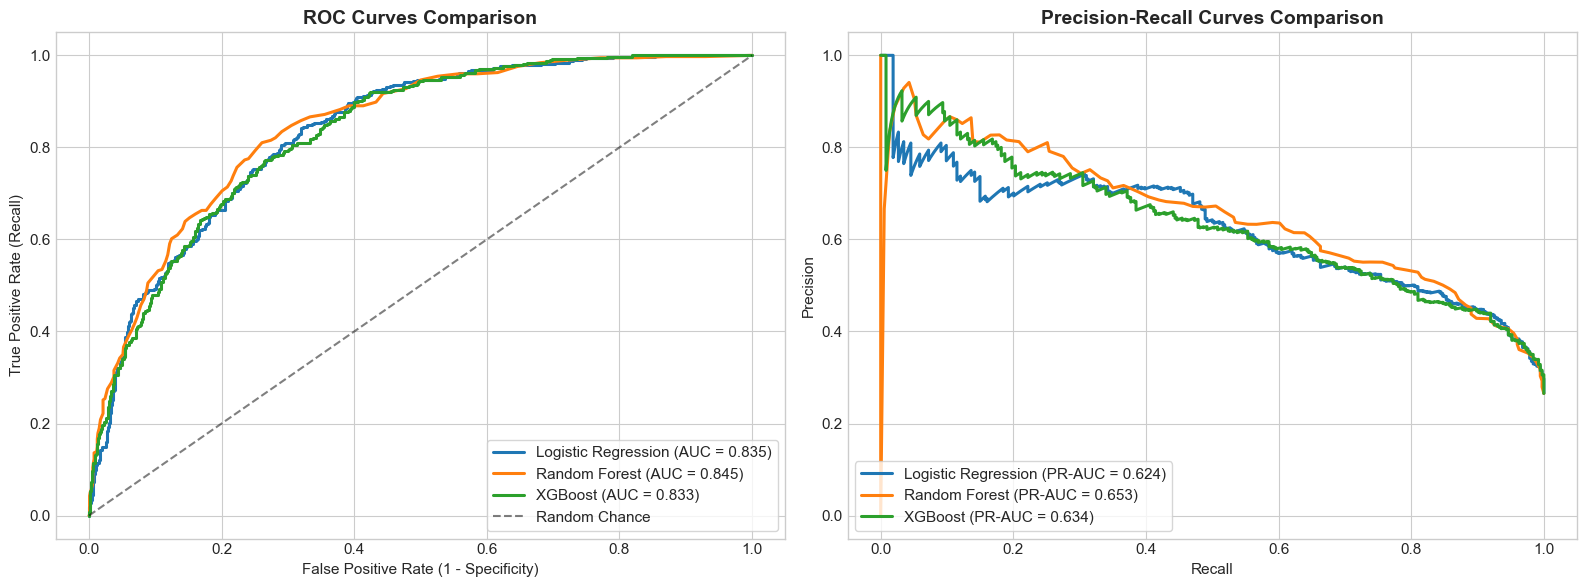

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc_val = roc_auc_score(y_test, probabilities[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", linewidth=2.2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance')
axes[0].set_title('ROC Curves Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right', frameon=True)

for name in models.keys():
    prec, rec, _ = precision_recall_curve(y_test, probabilities[name])
    pr_auc = average_precision_score(y_test, probabilities[name])
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC = {pr_auc:.3f})", linewidth=2.2)

axes[1].set_title('Precision-Recall Curves Comparison', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()


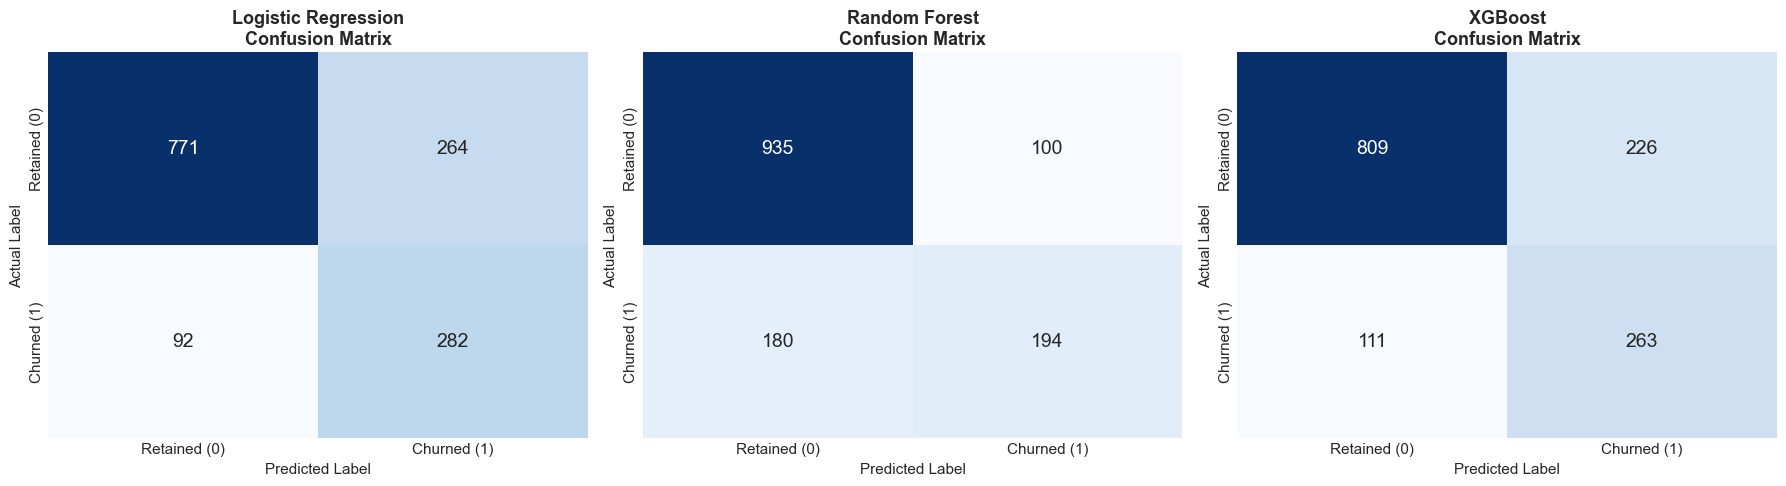

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                cbar=False, annot_kws={'size': 14})
    axes[i].set_title(f'{name}\nConfusion Matrix', fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label')
    axes[i].set_xticklabels(['Retained (0)', 'Churned (1)'])
    axes[i].set_yticklabels(['Retained (0)', 'Churned (1)'])

plt.tight_layout()
plt.show()


In [9]:
param_grid = {
    'n_estimators': [100, 150],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0]
}

grid_search = GridSearchCV(
    XGBClassifier(scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42),
    param_grid, cv=3, scoring='roc_auc', n_jobs=-1, verbose=0
)
grid_search.fit(X_train, y_train)

best_xgb = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)

y_pred_tuned = best_xgb.predict(X_test)
y_prob_tuned = best_xgb.predict_proba(X_test)[:, 1]

print("\n=== Tuned XGBoost Performance ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_tuned):.4f}")


Best Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100, 'subsample': 0.8}



=== Tuned XGBoost Performance ===
Accuracy:  0.7537
Recall:    0.7861
Precision: 0.5241
F1-Score:  0.6289
ROC-AUC:   0.8520


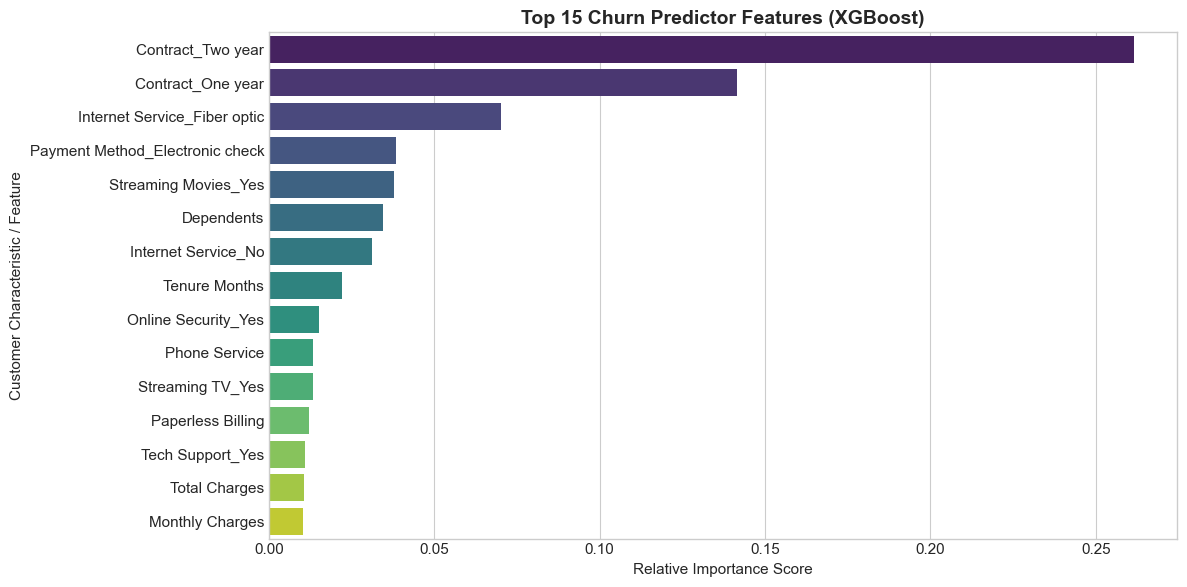

Top 5 Drivers of Churn:
1. Contract_Two year (Importance: 0.2615)
2. Contract_One year (Importance: 0.1414)
3. Internet Service_Fiber optic (Importance: 0.0701)
4. Payment Method_Electronic check (Importance: 0.0383)
5. Streaming Movies_Yes (Importance: 0.0379)


In [10]:
importances = best_xgb.feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
top_15 = feat_imp.head(15)
sns.barplot(x=top_15.values, y=top_15.index, palette='viridis')
plt.title('Top 15 Churn Predictor Features (XGBoost)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.ylabel('Customer Characteristic / Feature')
plt.tight_layout()
plt.show()

print("Top 5 Drivers of Churn:")
for rank, (feat, val) in enumerate(top_15.head(5).items(), 1):
    print(f"{rank}. {feat} (Importance: {val:.4f})")


In [11]:
os.makedirs('../src/churn_predictor/models', exist_ok=True)
model_path = '../src/churn_predictor/models/best_churn_model.joblib'

joblib.dump(best_xgb, model_path)
print(f"✅ Best Churn Model saved to: {model_path}")
print("✅ Ready for AWS Cloud MLOps pipeline deployment!")


✅ Best Churn Model saved to: ../src/churn_predictor/models/best_churn_model.joblib
✅ Ready for AWS Cloud MLOps pipeline deployment!
